In [1]:
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, Subset, random_split
import pandas as pd
import random

from src.dataset import LOLv2Dataset
from train import train, evaluate_model, summarize_metrics, apply_clahe

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED = 42

In [2]:
# test data pipeline batch
ROOT = "./dataset/LOL-v2/Real_captured"

train_full_dataset = LOLv2Dataset(
    root=ROOT,
    split="Train",
    patch_size=256,
    augment=True
)

test_dataset = LOLv2Dataset(
    root=ROOT,
    split="Test",
    augment=False
)

train_size = int(0.9 * len(train_full_dataset))
val_size = (len(train_full_dataset) - train_size)

split_generator = torch.Generator().manual_seed(SEED)

train_dataset, val_dataset = random_split(
    train_full_dataset,
    [train_size, val_size],
    generator=split_generator
)

# Load the data into torch (this is kinda painful to change cuz i dont have config maybe later lol)
train_loader = DataLoader(
    train_dataset, batch_size=8, shuffle=True,
    generator=torch.Generator().manual_seed(SEED),   # seed-dependent shuffling
    pin_memory=(device.type == "cuda"),
)
val_loader = DataLoader(
    val_dataset, batch_size=8, shuffle=False,
    pin_memory=(device.type == "cuda"),
)

# Batch size 1 avoids issues if test image sizes differ
test_loader = DataLoader(
    test_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0
)

# Inspect one batch
low, normal = next(iter(train_loader))

print("Low shape:", low.shape)
print("Normal shape:", normal.shape)

print("Low range:", low.min().item(), low.max().item())
print("Normal range:", normal.min().item(), normal.max().item())

Train: 689 image pairs loaded
Test: 100 image pairs loaded
Low shape: torch.Size([8, 3, 256, 256])
Normal shape: torch.Size([8, 3, 256, 256])
Low range: 0.0 0.6392157077789307
Normal range: 0.0 1.0


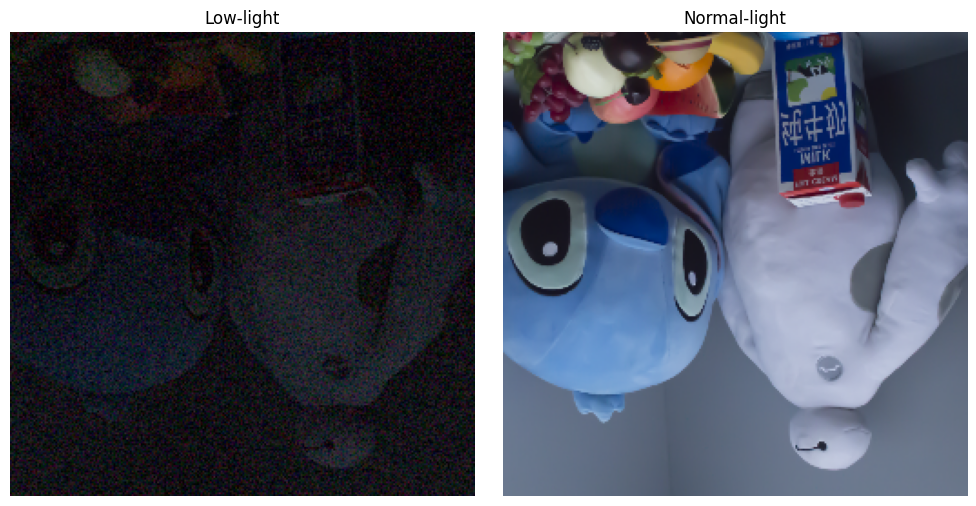

In [3]:
# visualize 1 set of images
low, normal = train_dataset[0]

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(low.permute(1, 2, 0))
axes[0].set_title("Low-light")

axes[1].imshow(normal.permute(1, 2, 0))
axes[1].set_title("Normal-light")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# test Direct CNN model
model, history, best = train(SEED, train_loader, val_loader, 200, 1e-3, len(train_dataset), len(val_dataset), load=True)

Output shape: torch.Size([3, 256, 256])


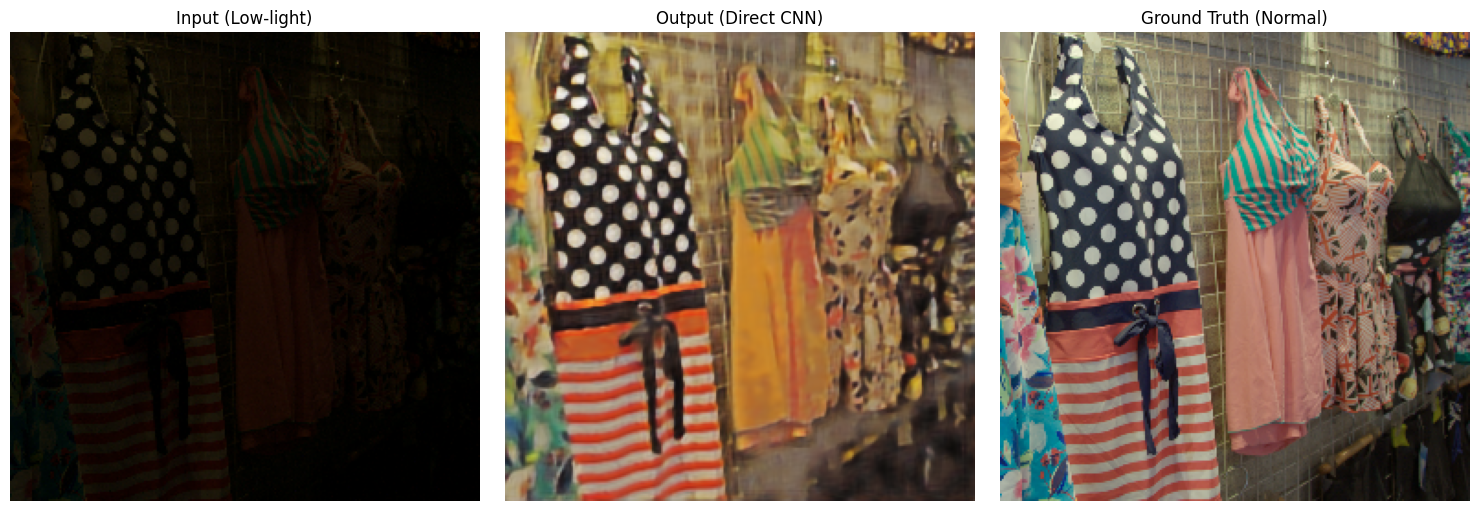

In [15]:
# visualize the output
model.eval()

# visualization config
pic_random = random.randint(0, 99)
low, normal = train_dataset[pic_random]
low_input = low.unsqueeze(0).to(device) # return batch dimension: (3, H, W) -> (1, 3, H, W)

# CLAHE Config
clahe = True
clahe_clip = 4.0
clahe_tile = (8, 8)

# Inference
with torch.no_grad():
    output = model(low_input)

# Remove batch dimension and move to CPU
output = output.squeeze(0).cpu()

print("Output shape:", output.shape)
if clahe:
    apply_clahe(output, clip_limit=clahe_clip, tile_grid=clahe_tile)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

images = [
    low,
    output,
    normal
]

titles = [
    "Input (Low-light)",
    "Output (Direct CNN)",
    "Ground Truth (Normal)"
]

for ax, img, title in zip(axes, images, titles):
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [17]:
# evaluate the model
df = evaluate_model(model, SEED, test_dataset, clahe=True, clahe_clip=clahe_clip, clahe_tiles=clahe_tile)

summarize_metrics(df)

print("\nPublished Input row:")
print("MLI 0.0500 ± 0.0314 | CI 0.0443 ± 0.0286 | E 4.5533 ± 0.7764 | AG 0.0129 ± 0.0067")


Evaluating seed 42...

METRIC SUMMARY (SD over images, ddof=1)
                MLI Mean ± SD     CI Mean ± SD      E Mean ± SD     AG Mean ± SD    PSNR Mean ± SD   SSIM Mean ± SD
Method                                                                                                             
Input         0.0569 ± 0.0306  0.0423 ± 0.0243  4.7113 ± 0.6530  0.0096 ± 0.0040   9.7182 ± 1.9037  0.1960 ± 0.1103
Output        0.4875 ± 0.0883  0.1297 ± 0.0292  6.7765 ± 0.4155  0.0218 ± 0.0095  16.6036 ± 3.5660  0.6900 ± 0.0698
Output+CLAHE  0.5195 ± 0.0423  0.2115 ± 0.0338  7.6687 ± 0.2293  0.0527 ± 0.0201  12.8260 ± 1.7024  0.4396 ± 0.0838
Ground Truth  0.3706 ± 0.0763  0.1451 ± 0.0441  6.8867 ± 0.3865  0.0266 ± 0.0139         nan ± nan        nan ± nan

Published Input row:
MLI 0.0500 ± 0.0314 | CI 0.0443 ± 0.0286 | E 4.5533 ± 0.7764 | AG 0.0129 ± 0.0067
